# Notebook 4: 20-year production forecast of the 10 history-matched cases

**Reads:** `hist_match_output/` (the 10 cases from notebook 3), `hist_match_input/` (the proxy, for the posterior band), `data_after_engineering/` (history, forecast dates), `dataset_ori/09 Template Deliverable.xlsx`.
**Writes:** `forecast_output/` with `10_Final_deliverables.xlsx` (the deliverable), CSVs and figures. Method choices: `summary_forecast.md`.

```
 10 history-matched cases (cumulative gas, oil, water, 1998-2008)
            |
  [1] quarter rates; water-oil ratio; liquid rate
            |
  [2] BACKTEST on 100 simulated cases + the observed field: cut at 2005, 2006, 2007,
      forecast to 2008, compare -> choose method, fit window, WOR anchoring, ensemble
            |
  [3] START-POINT HINDCAST: blind matches at 2005/2006/2007 on 100 pseudo-fields + the field
      -> start from each case's own state, or from the observed state?
            |
  [4] FORECAST each case 2008-04-01 .. 2028-01-01 (80 quarters); gas = GOR x oil
            |
  [5] start sensitivities ; uncertainty bands ; field reference
            |
  [6] DELIVERABLE: the 09 template filled (Case 1-10), validated on readback
```

**The forecasting problem.** The simulated cases stop at 2008-01-01. No simulator run exists after it, so the 20-year forecast cannot be learned from data the way the proxy was. Each case is extended with a petroleum-engineering forecast method fitted to its own late history. The methods are chosen by a **backtest**: hide the last 1-3 years of the 100 simulated cases and of the real field, forecast them, and compare with what happened.

**Organiser's instructions** (kick-off slides 26, 30, 31; `instruction/`): forecast field production over the next 20 years; "pick the best 10 forecast cases"; fill the template (Date, gas, oil and water production cumulative, quarterly from 04/01/2008); rock properties are static; no new wells after 2008 (team confirmation).

**Team decisions (15 Oct):** future water injection is held constant at its last value. The start point was first set to each case's own 2008 values (version 2, archived in `archive/v2_pre_bias_fix_2026-10-15/`). The team then agreed to test fixes for the 2008 rate bias and keep them only if they improved the forecast significantly. The blind hindcast in section 4 showed that they did, so **each forecast now starts from the observed 2008 cumulative and rates (A2)**, with the case supplying the shape. The own-start forecast is kept as a sensitivity.

In [1]:
import os, sys, json, time, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import torch

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_after_engineering").exists())
sys.path.insert(0, str(ROOT / "src"))
import proxy_lib as pl
import forecast_lib as fl

DATA_DIR = ROOT / "data_after_engineering"
HM_IN, HM_OUT = ROOT / "hist_match_input", ROOT / "hist_match_output"
TEMPLATE = ROOT / "dataset_ori" / "09 Template Deliverable.xlsx"
FC_DIR = ROOT / "forecast_output"; FIG_DIR = FC_DIR / "figs"
FC_DIR.mkdir(exist_ok=True); FIG_DIR.mkdir(exist_ok=True)
DELIVERABLE = FC_DIR / "10_Final_deliverables.xlsx"
torch.set_num_threads(2)
OIL, GAS, WATER = fl.OIL, fl.GAS, fl.WATER          # model phase order: oil, gas, water

INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE_600, BLUE_450, BLUE_250, ORANGE, AQUA = "#184f95", "#2a78d6", "#86b6ef", "#eb6834", "#1baf7a"
PH_COL = {"oil": BLUE_450, "gas": ORANGE, "water": AQUA}
plt.rcParams.update({"font.family": "sans-serif", "font.size": 9, "figure.facecolor": SURF, "axes.facecolor": SURF,
                     "savefig.facecolor": SURF, "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED})


def _ax(ax):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.tick_params(labelsize=8)
    return ax


def _finish(fig, name, title=None):
    if title:
        fig.suptitle(title, x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout(); fig.savefig(FIG_DIR / f"{name}.png", dpi=130); plt.show()

## 1. Data

* **History** (`history_observed.csv`): cumulative oil, gas and water on the 41 quarterly dates, and the water injection rate.
* **Simulated cases** (`curves_quarterly_cum.npz`): the 100 cases, used for the backtest only.
* **The 10 cases** (`hist_match_output/top10_*`): their 1998-2008 curves (simulator curves for simulated cases, proxy curves for new parameter sets).
* **Forecast dates** (`forecast_dates.csv`): the 80 template dates, 2008-04-01 to 2028-01-01.

Rates are quarter means: (cumulative at a date - cumulative a quarter earlier) / days. The same definition is used for every curve.

In [2]:
D = pl.load_data("cumulative")                    # Y (100, 41, 3) and y_hist in oil, gas, water order
Y_SIM, YH, T = D["Y"], D["y_hist"], D["t_days"]
DATES = pd.DatetimeIndex(D["dates"])
HIST = pd.read_csv(DATA_DIR / "history_observed.csv")
INJ = HIST["water_inj_rate"].to_numpy(float)
INJ_FUTURE = float(INJ[-1])                        # team decision: constant after 2008
FD = pd.read_csv(DATA_DIR / "forecast_dates.csv", parse_dates=["date"])
T_OUT = FD["t_days"].to_numpy(float)
K_END = len(T) - 1                                 # index of 2008-01-01

TOP = pd.read_csv(HM_OUT / "top10_cases_real.csv")
SER = pd.read_csv(HM_OUT / "top10_series_real.csv")
C10 = np.stack([SER[SER["rank"] == r].sort_values("date")[["oil_cum", "gas_cum", "water_cum"]].to_numpy(float)
                for r in TOP["rank"]])            # (10, 41, 3) oil, gas, water
LABELS = [f"Case {r}: " + (f"sim {int(c)}" if s == "simulated" else "new set") for r, s, c in zip(TOP["rank"], TOP["source"], TOP["case_id"])]
assert C10.shape == (10, len(T), 3) and len(T_OUT) == 80
print(f"history to {DATES[-1].date()}; forecast {FD.date.iloc[0].date()} to {FD.date.iloc[-1].date()} ({len(T_OUT)} quarters)")
print(f"water injection: {INJ[4]:,.0f} STB/d (1999) -> {INJ[-1]:,.0f} STB/d (2008); held at {INJ_FUTURE:,.0f} STB/d after 2008")

QH = fl.quarter_rates(YH[None], T)[0]
Q10 = fl.quarter_rates(C10, T)
tab = pd.DataFrame({"case": ["observed"] + LABELS,
                    "oil_rate_2008": np.r_[QH[-1, OIL], Q10[:, -1, OIL]],
                    "water_rate_2008": np.r_[QH[-1, WATER], Q10[:, -1, WATER]],
                    "oil_cum_2008_MM": np.r_[YH[-1, OIL], C10[:, -1, OIL]] / 1e6,
                    "water_cum_2008_MM": np.r_[YH[-1, WATER], C10[:, -1, WATER]] / 1e6})
print("\nRates (last quarter, STB/d) and cumulatives (MMSTB) on 2008-01-01:")
print(tab.round(2).to_string(index=False))

history to 2008-01-01; forecast 2008-04-01 to 2028-01-01 (80 quarters)
water injection: 12,098 STB/d (1999) -> 9,327 STB/d (2008); held at 9,327 STB/d after 2008

Rates (last quarter, STB/d) and cumulatives (MMSTB) on 2008-01-01:
           case  oil_rate_2008  water_rate_2008  oil_cum_2008_MM  water_cum_2008_MM
       observed        5246.80          7782.27            38.38              12.81
  Case 1: sim 6        5955.48          6999.58            38.62              12.54
Case 2: new set        5939.29          7035.22            38.60              12.55
Case 3: new set        5912.75          7029.07            38.59              12.54
Case 4: new set        5920.64          6993.84            38.61              12.53
Case 5: new set        5903.55          6999.09            38.59              12.55
Case 6: new set        5972.94          6982.73            38.64              12.56
 Case 7: sim 97        6015.35          7013.71            38.62              12.58
 Case 8: sim 7

**Reading.** The 10 cases match the observed *cumulatives* within about 1-2 %, but their *rates* in the last quarter differ more: oil is higher and water lower than the field's. This is the same water under-match reported in `summary_hist_mat.md`, now visible at the end of the history, where the forecast starts. Section 4 tests what this means for the forecast.

## 2. Forecast methods

| Code | Method | Oil | Water | Source |
|---|---|---|---|---|
| `elton` | Elton's cumulative families (baseline) | Arps-type cumulative curve fitted to the whole 1998-2008 curve | Gompertz curve fitted to the whole curve | `our_work/proxy_model_elton/forecast_pipeline.py` |
| `arps_wor` | Decline curve + water-oil ratio trend | Arps hyperbolic rate decline fitted on the last *n* quarters, b in [0, 1], **modified hyperbolic**: switch to exponential at a terminal decline of 5 %/yr | ln(WOR) linear in cumulative oil, so water = WOR x oil | Arps (1945); Robertson's terminal decline; Wright (1958), Ershaghi & Omoregie (1978) |
| `liq_wor` | Liquid trend + WOR split | Liquid rate with an exponential (non-increasing) trend, split by the WOR trend | Same | Fractional-flow / water-cut extrapolation |
| `crm_wor` | Capacitance-resistance model (tank) + WOR split | Liquid rate from injection: q_L relaxes to G x injection with time constant tau; injection held at its 2008 value | Same | Sayarpour et al. (2007, 2009); CRM + fractional flow (Cao 2014; Oliveira et al. 2021) |

* **Gas** = GOR x oil, with the GOR of the case's last 4 quarters (about 0.3633 in every case and in the field).
* **WOR anchoring** (an option tested in the backtest): `fit` uses the least-squares line; `last` keeps its slope but moves it through the last 2 quarters' WOR, to remove the lag of a line fitted over the whole window.
* **Physical rules.** Cumulatives only increase; the oil decline rate is never negative (no new wells); water cut stays below 1 (WOR > 0); the forecast is continuous with its 2008 start values (the observed ones, section 4).
* **Why not continue the proxy in time.** The proxy maps parameters to the 41 dates it was trained on. There is no training data after 2008, so it cannot forecast. Si Jie's recurrent networks, which can run past 2008, flattened their oil decline after 2010 (`our_work/proxy_model_sijie/summary.md`, limitation 1).

## 3. Backtest: choose the method

**Design.** For each cut-off (2005-01-01, 2006-01-01, 2007-01-01), each method uses only the data up to the cut-off and forecasts to 2008-01-01 (12, 8 and 4 quarters ahead). The forecast is compared with the truth on **all 100 simulated cases** and on **the observed field**. Elton's backtest used one split (fit on quarters 1-25, score 26-41) on the cases only.

**Error measure.** Relative error of the volume produced between the cut-off and 2008-01-01, per phase: (forecast - actual) / actual. Summaries over the 100 cases: the median absolute error and the median signed error (bias).

**Settings searched:** fit window n = 8, 12 or 16 quarters; WOR anchoring `fit` or `last`. Water injection after the cut-off is held at its cut-off value, as in the real forecast.

**Choice.** The score of a setting = mean over the 3 cut-offs of (median |error| oil + median |error| water) / 2 on the cases. The field is reported next to it as a check. The best setting of each method is kept; then the average of the two best methods (an ensemble) is tested the same way.

In [3]:
CUTS = [28, 32, 36]
WINDOWS = [8, 12, 16]
CURVES = np.concatenate([Y_SIM, YH[None]])         # 100 cases + the field (last row)
FIELD = len(CURVES) - 1


def produced_error(dNo, dNw, C, kc):
    truth_o, truth_w = C[K_END, OIL] - C[kc, OIL], C[K_END, WATER] - C[kc, WATER]
    return (dNo[-1] - truth_o) / truth_o * 100, (dNw[-1] - truth_w) / truth_w * 100


def run_setting(method, n, anchor, kc):
    tout = T[kc + 1:]
    E = np.empty((len(CURVES), 2))
    for i, C in enumerate(CURVES):
        E[i] = produced_error(*fl.forecast_case(method, C, T, kc, tout, n, INJ, INJ[kc], wor_anchor=anchor), C, kc)
    return E


t0 = time.time()
rows, ERR = [], {}
for kc in CUTS:
    tout = T[kc + 1:]
    dNo, dNw = fl.forecast_elton(CURVES, T, kc, tout)
    E = np.array([produced_error(dNo[i], dNw[i], CURVES[i], kc) for i in range(len(CURVES))])
    ERR[("elton", 0, "-", kc)] = E
    for m in ("arps_wor", "liq_wor", "crm_wor"):
        for n in WINDOWS:
            for anchor in ("fit", "last"):
                ERR[(m, n, anchor, kc)] = run_setting(m, n, anchor, kc)
for (m, n, anchor, kc), E in ERR.items():
    rows.append({"method": m, "window": n, "wor_anchor": anchor, "cutoff": str(DATES[kc].date()), "horizon_q": K_END - kc,
                 "cases_med_abs_oil_%": np.median(np.abs(E[:FIELD, 0])), "cases_med_abs_water_%": np.median(np.abs(E[:FIELD, 1])),
                 "cases_bias_oil_%": np.median(E[:FIELD, 0]), "cases_bias_water_%": np.median(E[:FIELD, 1]),
                 "field_oil_%": E[FIELD, 0], "field_water_%": E[FIELD, 1]})
BT = pd.DataFrame(rows)
BT.to_csv(FC_DIR / "backtest_all_settings.csv", index=False)
print(f"backtest: {len(ERR)} setting x cut-off runs on {len(CURVES)} curves in {time.time() - t0:.0f} s")

agg = BT.groupby(["method", "window", "wor_anchor"]).agg(
    oil=("cases_med_abs_oil_%", "mean"), water=("cases_med_abs_water_%", "mean"),
    bias_oil=("cases_bias_oil_%", "mean"), bias_water=("cases_bias_water_%", "mean"),
    field_oil=("field_oil_%", lambda x: np.mean(np.abs(x))), field_water=("field_water_%", lambda x: np.mean(np.abs(x)))).reset_index()
agg["score"] = (agg["oil"] + agg["water"]) / 2
agg["field_score"] = (agg["field_oil"] + agg["field_water"]) / 2
BEST = agg.loc[agg.groupby("method")["score"].idxmin()].sort_values("score").reset_index(drop=True)
BEST.to_csv(FC_DIR / "backtest_best_per_method.csv", index=False)
print("\nBest setting of each method (mean over the 3 cut-offs; errors in % of the produced volume):")
print(BEST.round(2).to_string(index=False))

backtest: 57 setting x cut-off runs on 101 curves in 27 s

Best setting of each method (mean over the 3 cut-offs; errors in % of the produced volume):
  method  window wor_anchor   oil  water  bias_oil  bias_water  field_oil  field_water  score  field_score
 crm_wor      12       last  2.80   3.08     -1.89       -2.09       2.60         5.31   2.94         3.95
arps_wor      12       last  4.67   4.26     -3.04       -4.08       2.53         7.29   4.47         4.91
 liq_wor      16        fit  4.85   6.02     -4.15       -2.34       4.14         8.05   5.44         6.09
   elton       0          - 62.30  66.06     62.30      -66.06      61.80        70.21  64.18        66.00


In [4]:
# Ensemble: the average of the two best methods' added volumes, scored the same way
m1, m2 = BEST.iloc[0], BEST.iloc[1]
ens_rows = []
for kc in CUTS:
    E1, E2 = ERR[(m1.method, m1.window, m1.wor_anchor, kc)], ERR[(m2.method, m2.window, m2.wor_anchor, kc)]
    # errors are linear in the forecast volume, so the ensemble error is the mean of the two errors
    E = 0.5 * (E1 + E2)
    ERR[("ensemble", 0, "-", kc)] = E
    ens_rows.append({"cutoff": str(DATES[kc].date()), "oil": np.median(np.abs(E[:FIELD, 0])), "water": np.median(np.abs(E[:FIELD, 1])),
                     "field_oil": abs(E[FIELD, 0]), "field_water": abs(E[FIELD, 1])})
ENS = pd.DataFrame(ens_rows)
ens_score = (ENS["oil"].mean() + ENS["water"].mean()) / 2
print(f"ensemble of {m1.method} (n={m1.window}, {m1.wor_anchor}) and {m2.method} (n={m2.window}, {m2.wor_anchor}): "
      f"score {ens_score:.2f} % against {m1.score:.2f} % for {m1.method} alone")
USE_ENSEMBLE = bool(ens_score < m1.score)
FINAL = [m1, m2] if USE_ENSEMBLE else [m1]
FINAL_NAME = " + ".join(f"{m.method} (n={m.window}, WOR {m.wor_anchor})" for m in FINAL)
print("FINAL forecast method:", FINAL_NAME)

ensemble of crm_wor (n=12, last) and arps_wor (n=12, last): score 3.48 % against 2.94 % for crm_wor alone
FINAL forecast method: crm_wor (n=12, WOR last)


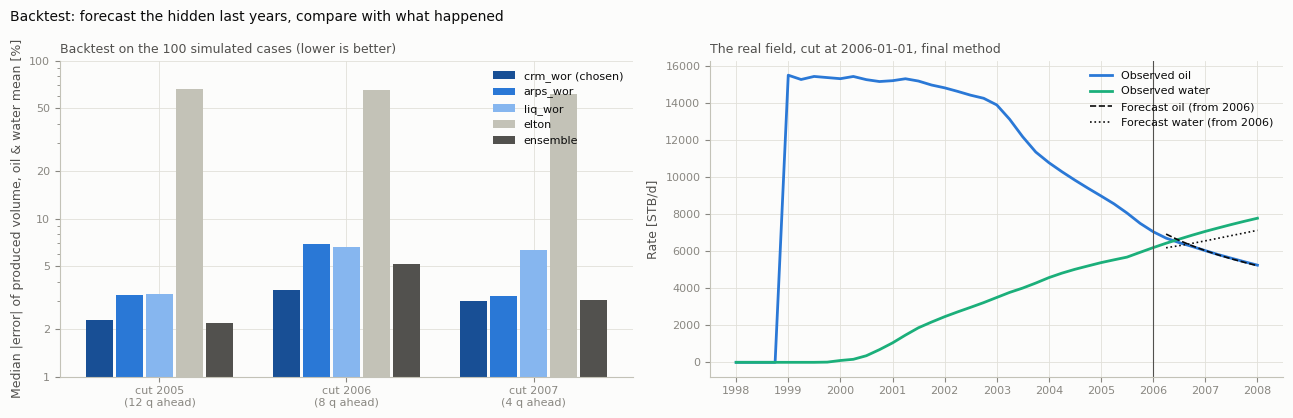

In [5]:
# Figure: backtest errors by method and cut-off, and the field example at the 2006 cut-off
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = _ax(axes[0])
names = list(BEST["method"]) + ["ensemble"]
x = np.arange(len(CUTS))
w = 0.8 / len(names)
for j, nm in enumerate(names):
    if nm == "ensemble":
        vals = [(np.median(np.abs(ERR[("ensemble", 0, "-", kc)][:FIELD, 0])) + np.median(np.abs(ERR[("ensemble", 0, "-", kc)][:FIELD, 1]))) / 2 for kc in CUTS]
    else:
        b = BEST[BEST.method == nm].iloc[0]
        vals = [(np.median(np.abs(ERR[(nm, b.window, b.wor_anchor, kc)][:FIELD, 0])) + np.median(np.abs(ERR[(nm, b.window, b.wor_anchor, kc)][:FIELD, 1]))) / 2 for kc in CUTS]
    col = {"elton": AXIS, "ensemble": INK2}.get(nm, [BLUE_600, BLUE_450, BLUE_250][min(j, 2)])   # BEST is sorted: darkest = best
    ax.bar(x + (j - len(names) / 2 + 0.5) * w, vals, w * 0.92, label=nm + (" (chosen)" if nm == FINAL[0].method and not USE_ENSEMBLE else ""),
           color=col)
ax.set_xticks(x); ax.set_xticklabels([f"cut {DATES[k].year}\n({K_END - k} q ahead)" for k in CUTS])
ax.set_ylabel("Median |error| of produced volume, oil & water mean [%]")
ax.set_yscale("log"); ax.legend(frameon=False, fontsize=8)
ax.set_yticks([1, 2, 5, 10, 20, 50, 100]); ax.set_yticklabels(["1", "2", "5", "10", "20", "50", "100"])
ax.set_title("Backtest on the 100 simulated cases (lower is better)", loc="left", fontsize=9, color=INK2)
ax = _ax(axes[1])
kc = 32
tout = T[kc + 1:]
for ph, j in [("oil", OIL), ("water", WATER)]:
    ax.plot(DATES, QH[:, j], color=PH_COL[ph], lw=2, label=f"observed {ph}")
for m in FINAL:
    dNo, dNw = fl.forecast_case(m.method, YH, T, kc, tout, int(m.window), INJ, INJ[kc], wor_anchor=m.wor_anchor)
    cum_o, cum_w = YH[kc, OIL] + dNo, YH[kc, WATER] + dNw
    q_o = np.diff(np.r_[YH[kc, OIL], cum_o]) / np.diff(np.r_[T[kc], tout])
    q_w = np.diff(np.r_[YH[kc, WATER], cum_w]) / np.diff(np.r_[T[kc], tout])
    ax.plot(DATES[kc + 1:], q_o, color=INK, lw=1.2, ls="--")
    ax.plot(DATES[kc + 1:], q_w, color=INK, lw=1.2, ls=":")
ax.axvline(DATES[kc], color=INK2, lw=0.8)
ax.set_ylabel("Rate [STB/d]")
ax.legend(handles=[Line2D([], [], color=PH_COL["oil"], lw=2, label="Observed oil"), Line2D([], [], color=PH_COL["water"], lw=2, label="Observed water"),
                   Line2D([], [], color=INK, lw=1.2, ls="--", label="Forecast oil (from 2006)"), Line2D([], [], color=INK, lw=1.2, ls=":", label="Forecast water (from 2006)")],
          frameon=False, fontsize=8)
ax.set_title("The real field, cut at 2006-01-01, final method", loc="left", fontsize=9, color=INK2)
_finish(fig, "backtest", "Backtest: forecast the hidden last years, compare with what happened")

## 4. Start point: blind hindcast

**The problem.** The 10 cases match the observed *cumulatives* within 1-3 %, but in 2008 their *rates* are 12-15 % high on oil and about 10 % low on water (section 1). No parameter set in the design removes this (`summary_hist_mat.md`, "Main limits"). A forecast that starts from each case's own state carries the gap for 20 years.

**The test.** Repeat the whole chain blind at an earlier date, then check against what happened.
* **Truths:** the real field, and each of the 100 simulated cases as a pseudo-field (the remaining 99 are the candidates).
* **Blind match:** at each cut-off (2005, 2006, 2007), the 10 simulated cases with the lowest oil + water cumulative misfit on 1999 to the cut-off only.
* **Forecast** each of the 10 to 2008-01-01 with the final method, from four starts:
  * `main`: the case's own cumulative and rates (the version 2 deliverable);
  * `A1`: the observed cumulative, the case's own rates;
  * `A2`: the observed cumulative and rates; the case supplies the shape (tau, G, WOR slope);
  * `fade_T`: the observed rates fading back to the case's own path over T days.
* **Error:** the mean of the 10 against the truth, as a % of the volume produced after the cut-off.

The pseudo-fields come from the same simulator as the candidates (in-family). The real field may not (the 2008 gap suggests it does not), so both are reported.

**Rule (agreed before the test):** switch from `main` only if the new start is better on the pseudo-fields (paired Wilcoxon, p < 0.01) **and** on the real field (mean over the 3 cut-offs).

In [6]:
t0 = time.time()
hc_rows = []
for kc in CUTS:
    for j in range(len(Y_SIM) + 1):
        truth = YH if j == len(Y_SIM) else Y_SIM[j]
        err = fl.hindcast_start(Y_SIM, truth, T, INJ, kc, K_END, exclude=None if j == len(Y_SIM) else j, fades=(365, 730))
        for opt, e in err.items():
            hc_rows.append({"truth": "field" if j == len(Y_SIM) else f"case_{j + 1}", "cutoff": str(DATES[kc].date()), "option": opt,
                            "err_oil_%": e[0], "err_water_%": e[1], "abs_mean": (abs(e[0]) + abs(e[1])) / 2})
HC = pd.DataFrame(hc_rows)
HC.to_csv(FC_DIR / "hindcast_start_all.csv", index=False)
PS, FLD = HC[HC.truth != "field"], HC[HC.truth == "field"]
HCS = PS.groupby("option").agg(pseudo_med_abs_oil=("err_oil_%", lambda x: np.median(np.abs(x))),
                               pseudo_med_abs_water=("err_water_%", lambda x: np.median(np.abs(x))),
                               pseudo_mean_abs=("abs_mean", "mean"))
HCS = HCS.join(FLD.pivot_table(index="option", columns="cutoff", values="abs_mean").add_prefix("field_"))
HCS["field_mean_abs"] = FLD.groupby("option")["abs_mean"].mean()
from scipy.stats import wilcoxon
base = PS[PS.option == "main"].set_index(["truth", "cutoff"])["abs_mean"]
for opt in HCS.index:
    o = PS[PS.option == opt].set_index(["truth", "cutoff"])["abs_mean"].loc[base.index]
    HCS.loc[opt, "pseudo_share_better_than_main_%"] = np.nan if opt == "main" else (o < base).mean() * 100
    HCS.loc[opt, "pseudo_wilcoxon_p_vs_main"] = np.nan if opt == "main" else wilcoxon(o, base).pvalue
HCS = HCS.sort_values("pseudo_mean_abs")
HCS.to_csv(FC_DIR / "hindcast_start_summary.csv")
print(f"hindcast: {len(CUTS)} cut-offs x {len(Y_SIM) + 1} truths in {time.time() - t0:.0f} s; errors in % of produced volume")
print(HCS.round(4).to_string())

cand = HCS.drop(index="main")
best = cand["pseudo_mean_abs"].idxmin()
ok = (HCS.loc[best, "pseudo_wilcoxon_p_vs_main"] < 0.01 and HCS.loc[best, "pseudo_mean_abs"] < HCS.loc["main", "pseudo_mean_abs"]
      and HCS.loc[best, "field_mean_abs"] < HCS.loc["main", "field_mean_abs"])
START = best if ok else "main"
print(f"\nSTART option: {START}  (best candidate {best}; passes the rule: {ok})")
assert START == "A2", "the start choice changed: update the text of sections 4-6 and summary_forecast.md"

hindcast: 3 cut-offs x 101 truths in 94 s; errors in % of produced volume
          pseudo_med_abs_oil  pseudo_med_abs_water  pseudo_mean_abs  field_2005-01-01  field_2006-01-01  field_2007-01-01  field_mean_abs  pseudo_share_better_than_main_%  pseudo_wilcoxon_p_vs_main
option                                                                                                                                                                                               
A2                    3.0044                2.8372           3.5219            5.1875            3.5525            2.6610          3.8003                          83.0000                        0.0
fade_730              2.9844                2.8275           3.6502            4.2522            3.8601            4.2498          4.1207                          82.3333                        0.0
fade_365              3.0274                2.8705           3.7237            3.8731            4.2149            5.4062          4.4

**Reading.**
* **Starting from the observed state wins in both worlds.**
  * On the pseudo-fields, A2 halves the error of `main` (3.5 % against 7.5 %) and is better in 83 % of the 300 pairs (Wilcoxon p ~ 1e-36).
  * On the real field, A2 also has the lowest mean error (3.8 % against 6.5 %).
  * Most of the gain on the pseudo-fields comes from the cumulative (A1). Anchoring the rates adds a further, significant gain: A2 is better than A1 in 73 % of the pairs (p ~ 3e-14, `improve_forecast/`).
* **The real field shows the 2008 problem directly.**
  * At the 2007 cut-off, the blind matches already run 8 % high on oil rate and 8 % low on water rate. Their own-start forecast misses the field's oil by about 11 % and its water by about 16 %; A2 misses them by 0.2 % and 5 %.
  * At the 2005 cut-off, before the gap opens, `main` is better (2.5 % against 5.2 %). The gain comes from the late cut-offs, which are the ones most like 2008.
* **Fading the anchor out does not help.** The longer the fade, the closer it is to A2, and A2 itself is best.
* **Only 3 field cut-offs exist,** so the field result alone is not statistically testable. The decision rests on the pseudo-fields (significant) and on the field agreeing in direction.

## 5. Forecast of the 10 cases (start: observed 2008 cumulative and rates, A2)

In [7]:
def forecast_curve(C, anchor_rates=None):
    # Added oil and water after 2008-01-01 at the 80 dates, final method (ensemble = mean of the methods).
    outs = [fl.forecast_case(m.method, C, T, K_END, T_OUT, int(m.window), INJ, INJ_FUTURE,
                             wor_anchor=m.wor_anchor, anchor_rates=anchor_rates) for m in FINAL]
    return np.mean([o[0] for o in outs], axis=0), np.mean([o[1] for o in outs], axis=0)


def build(C, start=None, anchor_rates=None):
    # Full cumulative forecast (80, 3) in oil, gas, water order. start: the 2008 cumulative to add to.
    start = C[K_END] if start is None else start
    dNo, dNw = forecast_curve(C, anchor_rates)
    gor = fl.gor_at_cut(C, T, K_END)
    F = np.empty((len(T_OUT), 3))
    F[:, OIL], F[:, WATER], F[:, GAS] = start[OIL] + dNo, start[WATER] + dNw, start[GAS] + gor * dNo
    return F


OBS_RATES = (QH[-1, OIL], QH[-1, WATER])
START_KW = {"start": YH[-1], "anchor_rates": OBS_RATES} if START == "A2" else {}
START_VALS = np.stack([YH[-1] if START == "A2" else C[K_END] for C in C10])  # (10, 3) the 2008 values each forecast continues
FC = np.stack([build(C, **START_KW) for C in C10])           # (10, 80, 3)
FQ = np.diff(np.concatenate([START_VALS[:, None, :], FC], axis=1), axis=1) / np.diff(np.r_[T[-1], T_OUT])[None, :, None]
checks = {
    "cumulatives never decrease": bool((np.diff(np.concatenate([START_VALS[:, None, :], FC], axis=1), axis=1) >= -1e-6).all()),
    "oil rate never increases (no new wells)": bool((np.diff(FQ[:, :, OIL], axis=1) <= 1e-6).all()),
    "water cut below 1": bool((FQ[:, :, WATER] / (FQ[:, :, OIL] + FQ[:, :, WATER]) < 1).all()),
    "all values finite and positive": bool(np.isfinite(FC).all() and (FC > 0).all()),
    "first-quarter rates within 10 % of the 2008 start rates": bool(
        (np.abs(FQ[:, 0, [OIL, WATER]] / (np.array(OBS_RATES)[None] if START == "A2" else Q10[:, -1, [OIL, WATER]]) - 1) < 0.10).all()),
}
for k, v in checks.items():
    print("PASS" if v else "FAIL", "-", k)
SUM = pd.DataFrame({"case": LABELS,
                    "oil_2008_MM": START_VALS[:, OIL] / 1e6, "oil_2028_MM": FC[:, -1, OIL] / 1e6,
                    "water_2008_MM": START_VALS[:, WATER] / 1e6, "water_2028_MM": FC[:, -1, WATER] / 1e6,
                    "gas_2028_MMMSCF": FC[:, -1, GAS] / 1e6,
                    "oil_rate_2028": FQ[:, -1, OIL], "water_cut_2028": FQ[:, -1, WATER] / (FQ[:, -1, OIL] + FQ[:, -1, WATER])})
SUM.to_csv(FC_DIR / "forecast_summary_by_case.csv", index=False)
print("\n" + SUM.round(3).to_string(index=False))

PASS - cumulatives never decrease
PASS - oil rate never increases (no new wells)
PASS - water cut below 1
PASS - all values finite and positive
PASS - first-quarter rates within 10 % of the 2008 start rates

           case  oil_2008_MM  oil_2028_MM  water_2008_MM  water_2028_MM  gas_2028_MMMSCF  oil_rate_2028  water_cut_2028
  Case 1: sim 6       38.378       58.694         12.814         85.286           21.328       1587.309           0.875
Case 2: new set       38.378       58.586         12.814         85.390           21.284       1572.334           0.876
Case 3: new set       38.378       58.485         12.814         85.339           21.247       1560.255           0.877
Case 4: new set       38.378       58.530         12.814         85.310           21.263       1566.378           0.876
Case 5: new set       38.378       58.483         12.814         85.371           21.246       1559.629           0.877
Case 6: new set       38.378       58.704         12.814         85.385 

## 6. Start sensitivities

The main forecast (A2) starts from the observed 2008 cumulatives and rates. For comparison:

* **Own start (version 2 main):** each case continues from its own 2008 cumulative and rates.
* **A1 - observed cumulative:** the own-start added volumes, put on top of the observed 2008 cumulatives (a shift).

In [8]:
FC_OWN = np.stack([build(C) for C in C10])
FC_A1 = np.stack([build(C, start=YH[-1]) for C in C10])
FC_A2 = np.stack([build(C, start=YH[-1], anchor_rates=OBS_RATES) for C in C10])
assert np.allclose(FC_A2, FC) if START == "A2" else np.allclose(FC_OWN, FC)
rows = []
for nm, F in [("main (A2): observed cumulative + rates", FC_A2), ("own start (version 2 main)", FC_OWN), ("A1: observed cumulative", FC_A1)]:
    for j, ph in [(OIL, "oil"), (WATER, "water"), (GAS, "gas")]:
        rows.append({"start": nm, "phase": ph, "P10_2028_MM": np.percentile(F[:, -1, j], 10) / 1e6,
                     "mean_2028_MM": F[:, -1, j].mean() / 1e6, "P90_2028_MM": np.percentile(F[:, -1, j], 90) / 1e6,
                     "mean_change_vs_main_%": (F[:, -1, j].mean() / FC[:, -1, j].mean() - 1) * 100})
ALT = pd.DataFrame(rows)
ALT.to_csv(FC_DIR / "alternative_start_comparison.csv", index=False)
print(ALT.round(3).to_string(index=False))

                                 start phase  P10_2028_MM  mean_2028_MM  P90_2028_MM  mean_change_vs_main_%
main (A2): observed cumulative + rates   oil       58.485        58.736       59.001                  0.000
main (A2): observed cumulative + rates water       85.170        85.287       85.385                  0.000
main (A2): observed cumulative + rates   gas       21.247        21.337       21.435                  0.000
            own start (version 2 main)   oil       60.704        61.155       61.688                  4.117
            own start (version 2 main) water       82.484        82.845       83.081                 -2.863
            own start (version 2 main)   gas       22.051        22.214       22.411                  4.109
               A1: observed cumulative   oil       60.493        60.891       61.349                  3.669
               A1: observed cumulative water       82.823        83.132       83.341                 -2.527
               A1: observed 

## 7. Uncertainty and a field reference

* **Across the 10 cases** (main forecast): P10 / P50 / P90 per date.
* **Across the posterior:** 200 parameter sets drawn from the MCMC posterior (`posterior_samples_real.csv`), their 1998-2008 curves from the proxy, each forecast with the final method and the same start. This carries the history-matching uncertainty to 2028.
* **Field reference:** the final method applied to the observed history itself (no model), as a data-only benchmark.
* **Wider range (for the slides and Power BI):** per date, the lowest and highest of the 10 cases (main), the 10 cases with their own start, and the field reference. In the hindcast the 10 cases' own range never contained the field's water (0 of 3 cut-offs), so the narrow case range understates the real uncertainty. This range adds the start and model choices.

In [9]:
from importlib import import_module
post = pd.read_csv(HM_OUT / "posterior_samples_real.csv")
draws = post[pl.PARAMS].sample(200, random_state=0).to_numpy()
proxy = pl.load_hm_proxy(HM_IN, DATES.values, ("oil_cum", "water_cum"))
full = proxy.full(draws)
CP = np.stack([full["oil_cum"], full["gas_cum"], full["water_cum"]], axis=-1)          # (200, 41, 3)
FP = np.stack([build(C, **START_KW) for C in CP])
FIELD_REF = build(YH)
WIDE = np.concatenate([FC, FC_OWN, FIELD_REF[None]])
pct = lambda A: np.percentile(A, [10, 50, 90], axis=0)
BANDS = []
for nm, A in [("10 cases", FC), ("posterior (200 sets)", FP), ("10 cases, own start (sensitivity)", FC_OWN)]:
    P = pct(A)
    for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
        BANDS.append(pd.DataFrame({"set": nm, "phase": ph, "date": FD["date"].dt.strftime("%Y-%m-%d"),
                                   "P10": P[0, :, j], "P50": P[1, :, j], "P90": P[2, :, j]}))
for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
    BANDS.append(pd.DataFrame({"set": "field reference (history only)", "phase": ph, "date": FD["date"].dt.strftime("%Y-%m-%d"),
                               "P10": FIELD_REF[:, j], "P50": FIELD_REF[:, j], "P90": FIELD_REF[:, j]}))
    # min / max (not percentiles) across the 10 cases, the own-start 10 and the field reference
    BANDS.append(pd.DataFrame({"set": "wider range (cases, own start, field reference): min / median / max", "phase": ph,
                               "date": FD["date"].dt.strftime("%Y-%m-%d"),
                               "P10": WIDE[:, :, j].min(axis=0), "P50": np.median(FC[:, :, j], axis=0), "P90": WIDE[:, :, j].max(axis=0)}))
BANDS = pd.concat(BANDS, ignore_index=True)
BANDS.to_csv(FC_DIR / "forecast_bands.csv", index=False)
b28 = BANDS[BANDS.date == "2028-01-01"].set_index(["set", "phase"])[["P10", "P50", "P90"]] / 1e6
print("Cumulative on 2028-01-01 (million STB / million MSCF):")
print(b28.round(2).to_string())

Cumulative on 2028-01-01 (million STB / million MSCF):
                                                                             P10    P50    P90
set                                                                 phase                     
10 cases                                                            oil    58.48  58.70  59.00
                                                                    gas    21.25  21.33  21.43
                                                                    water  85.17  85.30  85.39
posterior (200 sets)                                                oil    58.23  58.38  58.59
                                                                    gas    21.16  21.21  21.28
                                                                    water  85.00  85.20  85.46
10 cases, own start (sensitivity)                                   oil    60.70  61.09  61.69
                                                                    gas    22.05  22.19  2

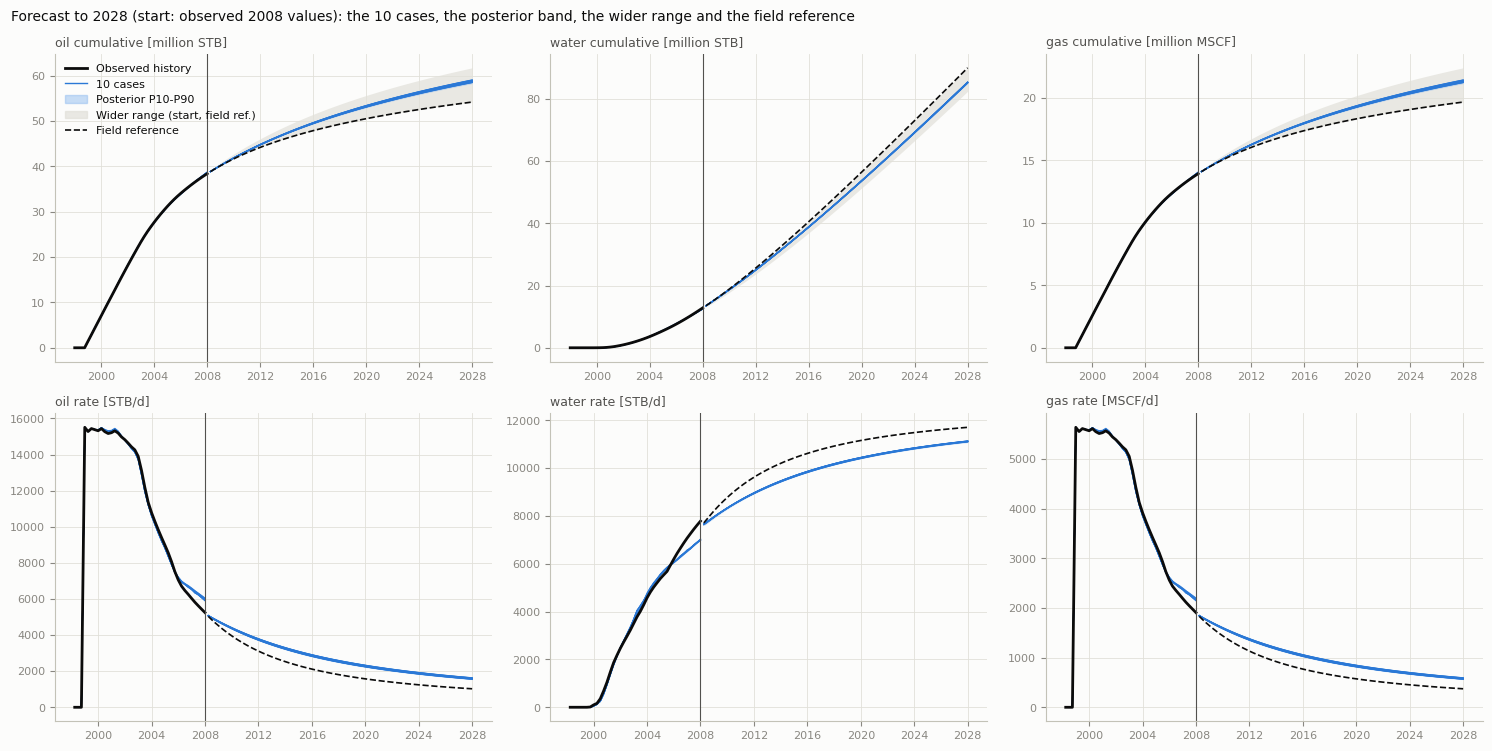

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6))
FDATES = pd.DatetimeIndex(FD["date"])
for col, (j, ph) in enumerate([(OIL, "oil"), (WATER, "water"), (GAS, "gas")]):
    ax = _ax(axes[0, col])
    ax.fill_between(FDATES, WIDE[:, :, j].min(axis=0) / 1e6, WIDE[:, :, j].max(axis=0) / 1e6, color=GRID, alpha=0.7, lw=0)
    P = pct(FP)
    ax.fill_between(FDATES, P[0, :, j] / 1e6, P[2, :, j] / 1e6, color=BLUE_250, alpha=0.45, lw=0)
    for i in range(10):
        ax.plot(DATES, C10[i, :, j] / 1e6, color=BLUE_450, lw=0.8, alpha=0.8)
        ax.plot(FDATES, FC[i, :, j] / 1e6, color=BLUE_450, lw=0.9, alpha=0.9)
    ax.plot(FDATES, FIELD_REF[:, j] / 1e6, color=INK, lw=1.2, ls="--")
    ax.plot(DATES, YH[:, j] / 1e6, color=INK, lw=2)
    ax.axvline(DATES[-1], color=INK2, lw=0.8)
    ax.set_title(f"{ph} cumulative [million {'MSCF' if ph == 'gas' else 'STB'}]", loc="left", fontsize=9, color=INK2)
    ax = _ax(axes[1, col])
    P_START = np.broadcast_to(YH[-1], CP[:, -1].shape) if START == "A2" else CP[:, -1]
    QP = np.diff(np.concatenate([P_START[:, None, :], FP], axis=1), axis=1) / np.diff(np.r_[T[-1], T_OUT])[None, :, None]
    P = pct(QP)
    ax.fill_between(FDATES, P[0, :, j], P[2, :, j], color=BLUE_250, alpha=0.45, lw=0)
    for i in range(10):
        ax.plot(DATES[1:], Q10[i, 1:, j], color=BLUE_450, lw=0.8, alpha=0.8)
        ax.plot(FDATES, FQ[i, :, j], color=BLUE_450, lw=0.9, alpha=0.9)
    ax.plot(DATES[1:], QH[1:, j], color=INK, lw=2)
    QF = np.diff(np.r_[YH[-1, j], FIELD_REF[:, j]]) / np.diff(np.r_[T[-1], T_OUT])
    ax.plot(FDATES, QF, color=INK, lw=1.2, ls="--")
    ax.axvline(DATES[-1], color=INK2, lw=0.8)
    ax.set_title(f"{ph} rate [{'MSCF' if ph == 'gas' else 'STB'}/d]", loc="left", fontsize=9, color=INK2)
axes[0, 0].legend(handles=[Line2D([], [], color=INK, lw=2, label="Observed history"), Line2D([], [], color=BLUE_450, lw=1, label="10 cases"),
                           Patch(color=BLUE_250, alpha=0.45, label="Posterior P10-P90"), Patch(color=GRID, alpha=0.7, label="Wider range (start, field ref.)"),
                           Line2D([], [], color=INK, lw=1.2, ls="--", label="Field reference")],
                  frameon=False, fontsize=8, loc="upper left")
_finish(fig, "forecast_fan", "Forecast to 2028 (start: observed 2008 values): the 10 cases, the posterior band, the wider range and the field reference")

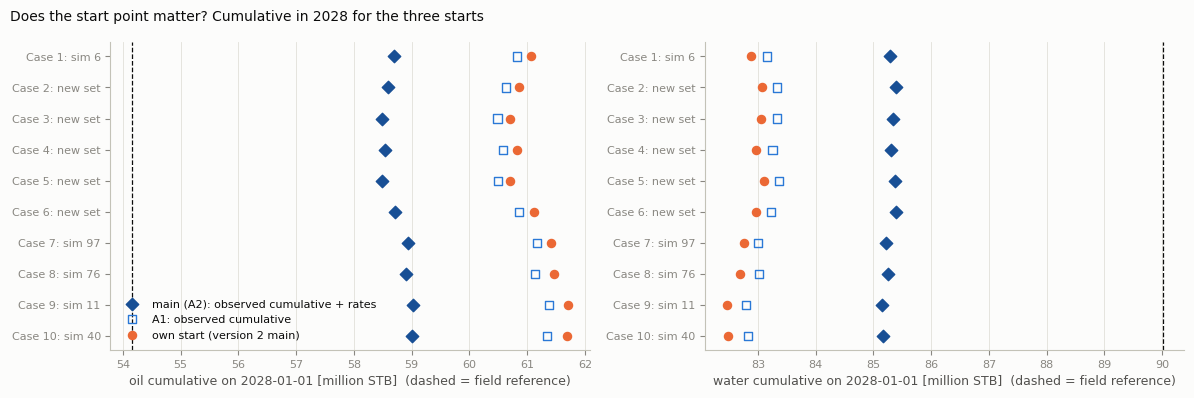

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax_, (j, ph) in zip(axes, [(OIL, "oil"), (WATER, "water")]):
    ax = _ax(ax_)
    y = np.arange(10)[::-1]
    ax.scatter(FC_A2[:, -1, j] / 1e6, y, s=40, marker="D", color=BLUE_600, label="main (A2): observed cumulative + rates", zorder=3)
    ax.scatter(FC_A1[:, -1, j] / 1e6, y, s=34, marker="s", facecolors="none", edgecolors=BLUE_450, label="A1: observed cumulative")
    ax.scatter(FC_OWN[:, -1, j] / 1e6, y, s=34, color=ORANGE, label="own start (version 2 main)")
    ax.axvline(FIELD_REF[-1, j] / 1e6, color=INK, lw=0.9, ls="--")
    ax.set_yticks(y); ax.set_yticklabels(LABELS, fontsize=8)
    ax.set_xlabel(f"{ph} cumulative on 2028-01-01 [million STB]  (dashed = field reference)")
    ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
_finish(fig, "alternative_start", "Does the start point matter? Cumulative in 2028 for the three starts")

## 8. Deliverable: the 09 template

`dataset_ori/09 Template Deliverable.xlsx` has 10 sheets (`Case 1` to `Case 10`), each with the columns **Date**, **Gas production cumulative [MSCF]**, **Oil production cumulative [STB]**, **Water production cumulative [STB]** and 80 quarterly rows (04/01/2008 to 01/01/2028). The template is copied, the value columns are filled with the main forecast (sheet `Case k` = history-matching rank k), and the Date column is left as it is. The file is read back and checked.

In [12]:
from openpyxl import load_workbook


def write_deliverable(F, out_path, template=TEMPLATE):
    wb = load_workbook(template)
    for k in range(10):
        ws = wb[f"Case {k + 1}"]
        assert ws.cell(1, 2).value.startswith("Gas") and ws.cell(1, 3).value.startswith("Oil") and ws.cell(1, 4).value.startswith("Water")
        for r in range(80):
            for col, j in [(2, GAS), (3, OIL), (4, WATER)]:
                cell = ws.cell(row=2 + r, column=col, value=float(np.round(F[k, r, j], 0)))
                cell.number_format = "0"
    wb.save(out_path)


write_deliverable(FC, DELIVERABLE)
report = {}
for k in range(10):
    name = f"Case {k + 1}"
    tpl = pd.read_excel(TEMPLATE, sheet_name=name, header=None)
    out = pd.read_excel(DELIVERABLE, sheet_name=name, header=None)
    vals = np.asarray(out.iloc[1:81, 1:4], dtype=float)
    report[name] = {
        "rows": int(vals.shape[0]),
        "dates_match_template": bool((tpl.iloc[:, 0].astype(str).to_numpy() == out.iloc[:, 0].astype(str).to_numpy()).all()),
        "headers_match": bool((tpl.iloc[0, :4].astype(str).to_numpy() == out.iloc[0, :4].astype(str).to_numpy()).all()),
        "finite": bool(np.isfinite(vals).all()),
        "monotone": bool((np.diff(vals, axis=0) >= -1e-6).all()),
        "continuous_with_2008": bool((vals[0] >= np.round(START_VALS[k, [GAS, OIL, WATER]]) - 1).all()),
        "matches_forecast": bool(np.allclose(vals, np.round(FC[k][:, [GAS, OIL, WATER]]), atol=0.5)),
    }
REP = pd.DataFrame(report).T
print(REP.to_string())
assert (REP.drop(columns="rows").all().all()) and (REP["rows"] == 80).all(), "deliverable validation failed"
print(f"\nwrote and validated {DELIVERABLE}")

        rows dates_match_template headers_match finite monotone continuous_with_2008 matches_forecast
Case 1    80                 True          True   True     True                 True             True
Case 2    80                 True          True   True     True                 True             True
Case 3    80                 True          True   True     True                 True             True
Case 4    80                 True          True   True     True                 True             True
Case 5    80                 True          True   True     True                 True             True
Case 6    80                 True          True   True     True                 True             True
Case 7    80                 True          True   True     True                 True             True
Case 8    80                 True          True   True     True                 True             True
Case 9    80                 True          True   True     True                 Tr

In [13]:
# Long table for Power BI and the slides: history and forecast, every case, rates and cumulatives
rows = []
for i in range(10):
    hist_q = Q10[i]
    for k in range(len(T)):
        for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
            rows.append((int(TOP["rank"][i]), LABELS[i], str(DATES[k].date()), "history (case)", ph, C10[i, k, j], hist_q[k, j]))
    for k in range(80):
        for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
            rows.append((int(TOP["rank"][i]), LABELS[i], str(FDATES[k].date()), "forecast", ph, FC[i, k, j], FQ[i, k, j]))
    FQ_OWN = np.diff(np.r_[C10[i, -1:, :], FC_OWN[i]], axis=0) / np.diff(np.r_[T[-1], T_OUT])[:, None]
    for k in range(80):
        for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
            rows.append((int(TOP["rank"][i]), LABELS[i], str(FDATES[k].date()), "forecast, own start (sensitivity)", ph, FC_OWN[i, k, j], FQ_OWN[k, j]))
for k in range(len(T)):
    for j, ph in [(OIL, "oil"), (GAS, "gas"), (WATER, "water")]:
        rows.append((0, "Observed field", str(DATES[k].date()), "history (observed)", ph, YH[k, j], QH[k, j]))
LONG = pd.DataFrame(rows, columns=["rank", "case", "date", "period", "phase", "cumulative", "rate_per_day"])
LONG.to_csv(FC_DIR / "forecast_cases_long.csv", index=False)
summary = {"final_method": FINAL_NAME, "ensemble": USE_ENSEMBLE, "injection_after_2008": INJ_FUTURE,
           "start": START, "start_hindcast": HCS.round(4).reset_index().to_dict(orient="records"),
           "backtest_best": BEST.round(4).to_dict(orient="records"), "checks": checks,
           "oil_2028_MM": {"P10": float(np.percentile(FC[:, -1, OIL], 10) / 1e6), "mean": float(FC[:, -1, OIL].mean() / 1e6),
                           "P90": float(np.percentile(FC[:, -1, OIL], 90) / 1e6)},
           "water_2028_MM": {"P10": float(np.percentile(FC[:, -1, WATER], 10) / 1e6), "mean": float(FC[:, -1, WATER].mean() / 1e6),
                             "P90": float(np.percentile(FC[:, -1, WATER], 90) / 1e6)},
           "oil_2028_MM_own_start": float(FC_OWN[:, -1, OIL].mean() / 1e6),
           "wider_range_2028_MM": {ph: [float(WIDE[:, -1, j].min() / 1e6), float(WIDE[:, -1, j].max() / 1e6)]
                                   for j, ph in [(OIL, "oil"), (WATER, "water"), (GAS, "gas")]},
           "field_reference_2028_MM": {"oil": float(FIELD_REF[-1, OIL] / 1e6), "water": float(FIELD_REF[-1, WATER] / 1e6)},
           "deliverable": str(DELIVERABLE.relative_to(ROOT))}
(FC_DIR / "forecast_run_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("saved to", FC_DIR)
for f in sorted(FC_DIR.glob("*.*")):
    print(f"  {f.name:<40} {f.stat().st_size / 1e3:>9.1f} kB")

saved to C:\Users\Yi Siang\Documents\UM\dwc_team_what_repo\forecast_output
  10_Final_deliverables.xlsx                    40.0 kB
  alternative_start_comparison.csv               1.0 kB
  backtest_all_settings.csv                      8.3 kB
  backtest_best_per_method.csv                   0.8 kB
  forecast_bands.csv                           126.2 kB
  forecast_cases_long.csv                      556.3 kB
  forecast_run_summary.json                      4.3 kB
  forecast_summary_by_case.csv                   1.6 kB
  hindcast_start_all.csv                       125.1 kB
  hindcast_start_summary.csv                     1.0 kB


## 9. Conclusions

The numbers are printed above and collected in `forecast_output/forecast_run_summary.json`; the method choices and their sources are in `summary_forecast.md`.

**Start point.** The forecast starts from the observed 2008 cumulatives and rates (A2), chosen by the blind hindcast in section 4. The version 2 own-start forecast is about 4 % higher on oil and 3 % lower on water in 2028; it is kept as a sensitivity and inside the wider range.

**Limits.** The backtest covers at most 12 quarters; the forecast covers 80. It is evidence for the method, not a proof of the 20-year accuracy. The forecast assumes constant water injection, no new wells and no change of operating conditions after 2008.